# 401 - Foundations of Convolutional Neural Networks

In [162]:
import numpy as np
from src.datasets import load_examples_mnist
from src.network import Network
import matplotlib.pyplot as plt
from src.optimizers import AdamOptimizer, MomentumOptimizer
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Revisiting MNIST - Shallow Network

In [182]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

training_data = load_examples_mnist(n_samples=60000)
X_train, X_val, y_train, y_val = train_test_split(*training_data, test_size=1/6, random_state=42)

net = Network(
    sizes = [784, 100, 10],
    activation_functions=["sigmoid", "sigmoid"],
    cost = "cross_entropy",
    max_epochs=60,
    mini_batch_size=10,
    learning_rate=2.5e-2,
    penalty="l2",
    alpha=5.0,
    monitor_accuracy=True,
    monitor_cost=True,
)

binarize = LabelBinarizer()

X_train_t = X_train.T / 255
y_train_t = binarize.fit_transform(y_train[:, np.newaxis]).T
X_val_t = X_val.T / 255
y_val_t = binarize.transform(y_val[:, np.newaxis]).T

net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
print(f"Training accuracy: {net.score(X_train_t, y_train_t):.1%}")
print(f"Validation accuracy: {net.score(X_val_t, y_val_t):.1%}")

Training accuracy: 100.0%
Validation accuracy: 98.0%


## Introducing Convolutional Networks

In classifying images with fully connected layers, we considered pixels as a single vertical stack of neurons and connected them to the hidden neurons and let the network learn the weights.

The problem with this is that it does not take into account the spatial structure of the image. How the pixels are related in space were not considered.

ConvNets gives a way to learn the spacial structure of the image by considering pixels as an array of neurons, which seems to be a more natural way of learning images.





### Local Receptive Fields
- A small region of the 28px x 28px image, called a *local receptive field*, is connected to a hidden neuron.
- Each connection learns a weight.
- To cover the entire image, start with the topmost leftmost small region and then slide by one step to the right. After reaching the topmost rightmost small region, slide one step down and, once again, slide from the leftmost small region up to the rightmost small region. Repeat.

| 1. Local Receptive Field | 2. Start at the topmost leftmost region | 3. Slide along the height and width to form the first hidden layer |
| --- | --- | --- |
| ![nielsen-1](references/nielsen-cnn-img1.png)</br> | ![nielsen-2](references/nielsen-cnn-img2.png) | ![nielsen-3](references/nielsen-cnn-img3.png) |
*\*images were taken from Nielsen's book*

**Example.**</br>
original shape: 28x28 </br>
small region: 5x5 <br>
number of slides from left to right: 24 (including the start) </br>
number of slides from top to bottom: 24 (including start) </br>
shape of resulting hidden layer: 24 x 24 </br>

Each hidden neuron is connected to a 5x5 region via 5x5 weights and one bias term, and **the 5x5 weights and 1 bias is shared among hidden neurons.**
$$
\mathbf{A} = \sigma(\mathbf{W}\circ \mathbf{X} + b)
$$
Where $\circ$ is the convolution operation defined as follows.
$$
(\mathbf{W}\circ \mathbf{X})[n,m] = \sum_{k_1,k_2 = -K}^{K} \mathbf{W}[k_1,k_2]\mathbf{X}[n+k_1,m+k_2]
$$
Because the weights $\mathbf{W}$ are shared, the hidden neurons learn the same feature of the image: A vertical edge, a horizontal edge, etc. The difference between a hidden neuron and another is that they learn the same feature in a different area of the image.

The mapping from the image to the hidden layer is often called a **feature map**. The weights $\mathbf{W}$ and the bias $b$ are called the **shared weights** and **shared bias**, respectively. $\mathbf{W},\, b$ are said to form a **kernel** or a **filter**.

Often more than one feature map is needed to be able to recognize images.

### Pooling Layers

After the feature maps, the activations are propagated into a **pooling layer** as a way to summarize (condense) the information obtained. The hidden neurons learn if a feature exists in the corresponding local receptive field of the image and its exact positional location. The idea is that pooling provides an indicator that a feature exists in a local receptive field, but throw away the information about positional location as it is not as important.

Similar to the feature map from the input layer to the hidden layer, the feature map from the hidden layer to the pooling layer takes a small region of the hidden layer and applies an aggregate function.

An aggregate function that is often used is $f(\cdot) = \max_{a_{p,q}}(\cdot)$ and we call this procedure of pooling **max-pooling**.

**Example.** </br>
Take a 2x2 subregion from the hidden layer and find the maximum of the values of the activations in the 2x2 subregion. </br>
As before, start from the topmost leftmost 2x2 subregion and slide along the height and width of the hidden layer, except this time the stride length is equal to the shape of the subregion. </br>
With a 24x24 hidden layer, the shape of the pooling layer would be 12x12.

![nielsen-img4](references/nielsen-cnn-img4.png)</br>
*\*image taken from Nielsen's book*

Topmost leftmost:
$$
\begin{align*}
    a^{(2)}_{0,0} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{l,m}
\end{align*}
$$

1,1-th pooling unit:
$$
\begin{align*}
    a^{(2)}_{1,1} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{1+l,1+m}
\end{align*}
$$

p,q-th pooling unit:
$$
\begin{align*}
    a^{(2)}_{p,q} = \max_{\substack{0\leq l \leq 1 \\ 0\leq m \leq 1}}a^{(1)}_{p+l,q+m}
\end{align*}
$$

### CNN Architecture for MNIST

![my_net_01](assets/my_net_01.png)

For efficient implementation of the forward and backward pass, we apply a preprocessing step on the image/layer before passing to the feature map. The preprocessing step takes each local receptive field, flattens it into a column vector, and then stacks the local receptive fields side-by-side.

In [312]:
def extract_field(arr,pos,K):
    n,m = pos
    return arr[n-K:n+K+1,m-K:m+K+1]

def img2col(arr, field_shape:int, stride:int=1):
    lcr_list = []
    K = (field_shape-1)//2
    for n in range(K,arr.shape[0]-K, stride):
        for m in range(K,arr.shape[1]-K, stride):
            lcr = extract_field(arr, (n,m), K)
            lcr_list.append(lcr.reshape(-1,1,order="F"))
    return np.column_stack(lcr_list)

def conv2d(arr, kernel, pad_width:int):
    kernel_shape = kernel.shape[0]
    arr_padded = np.pad(arr, pad_width=pad_width, mode="constant", constant_values=0)
    arr2col = img2col(arr_padded, kernel_shape)
    filter2row = np.flip(filter).copy().reshape(1, -1,order="F")
    n_out = arr_padded.shape[0] - kernel_shape + 1
    m_out = arr_padded.shape[1] - kernel_shape + 1
    return (filter2row @ arr2col).reshape(n_out, m_out)

class C

#### Forward pass
Consider an image sample and a fixed kernel.

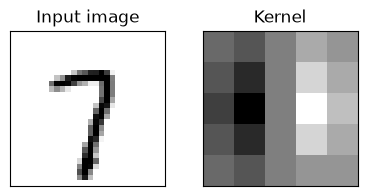

In [308]:
image_sample = X_train[2].reshape(28, 28)
kernel_ = np.array([     # Sobel kernel
    [1, 2, 0, -2, -1],
    [2, 4, 0, -4, -2],
    [3, 6, 0, -6, -3],
    [2, 4, 0, -4, -2],
    [1, 2, 0, -1, -1],
])
fig,axs = plt.subplots(1,2,figsize=(4,2),subplot_kw=dict(xticks=[],yticks=[]))
axs[0].imshow(image_sample/255, cmap="binary", interpolation="nearest")
axs[0].set_title("Input image")
axs[1].imshow(kernel_, cmap="binary", interpolation="nearest")
axs[1].set_title("Kernel")
plt.tight_layout()
plt.show()

The convolution will be obtained using the above implementation (`conv2d`) and pooling is done by downsampling the output of the convolution using Numpy functions.

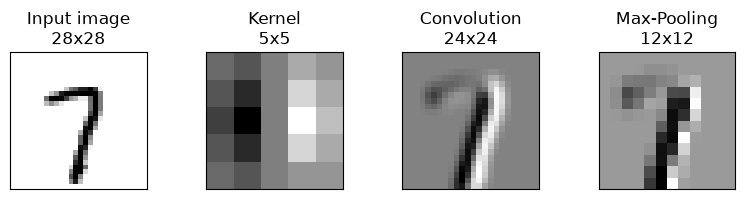

In [311]:
# Convolution
conv = conv2d(image_sample, kernel_, 0)

# Max-Pooling
pooling_shape = 2
pool = conv.reshape(conv.shape[0]//pooling_shape, pooling_shape, conv.shape[1]//pooling_shape, pooling_shape).max(axis=(1,3))

fig,axs = plt.subplots(1,4,figsize=(8,2),subplot_kw=dict(xticks=[],yticks=[]))
axs[0].imshow(image_sample/255, cmap="binary", interpolation="nearest")
axs[0].set_title(f"Input image\n{image_sample.shape[0]}x{image_sample.shape[1]}")
axs[1].imshow(kernel_, cmap="binary", interpolation="nearest")
axs[1].set_title(f"Kernel\n{kernel_.shape[0]}x{kernel_.shape[1]}")
axs[2].imshow(conv, cmap="binary", interpolation="nearest")
axs[2].set_title(f"Convolution\n{conv.shape[0]}x{conv.shape[1]}")
axs[3].imshow(pool, cmap="binary", interpolation="nearest")
axs[3].set_title(f"Max-Pooling\n{pool.shape[0]}x{pool.shape[1]}")
plt.tight_layout()

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Update:</strong> On second thought, I'm going to follow Nielsen's implementation: using a library that provides primitives for convolution forward and backward, and automatic differentiation. The library I'll be using is Pytorch! Most likely, I'll be using Pytorch anyway. So, I'll just translate some of Nielsen's implementation, based on Theano, to a Pytorch-based program.
</div>